In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../03-classification/data-week-3.csv')

In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [4]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
categorical_columns

['customerid',
 'gender',
 'partner',
 'dependents',
 'phoneservice',
 'multiplelines',
 'internetservice',
 'onlinesecurity',
 'onlinebackup',
 'deviceprotection',
 'techsupport',
 'streamingtv',
 'streamingmovies',
 'contract',
 'paperlessbilling',
 'paymentmethod',
 'totalcharges',
 'churn']

In [5]:
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [6]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')

In [7]:
df.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges        float64
churn                   str
dtype: object

In [8]:
df.totalcharges = df.totalcharges.fillna(0)

In [9]:
df.churn = (df.churn == 'yes').astype(int)

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [12]:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

In [13]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [14]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [15]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn
y_val = df_val.churn
y_test = df_test.churn

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [16]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[numerical + categorical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [17]:
model = LogisticRegression(
    solver='lbfgs',
    max_iter=10000
)

In [18]:
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [19]:
val_dict = df_val[numerical + categorical].to_dict(orient='records')

# Attention!!!
X_val = dv.transform(val_dict)

In [20]:
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)

# Accuracy = the fraction of predictions the model got right
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

### 02. Accuracy

In [21]:
from sklearn.metrics import accuracy_score

In [22]:
accuracy_score(y_val, y_pred >= .5)

0.8034066713981547

In [23]:
thresholds = np.linspace(0, 1, 21)
thresholds

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ])

In [24]:
scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.513
0.10 0.608
0.15 0.661
0.20 0.703
0.25 0.735
0.30 0.758
0.35 0.765
0.40 0.781
0.45 0.791
0.50 0.803
0.55 0.802
0.60 0.796
0.65 0.789
0.70 0.766
0.75 0.742
0.80 0.729
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


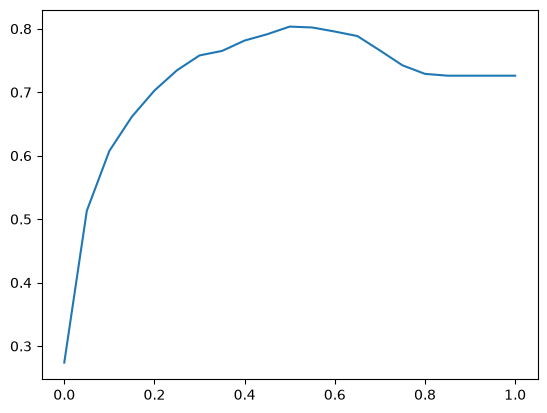

In [25]:
plt.plot(thresholds, scores)

#### === dummy model ===

In [26]:
from collections import Counter

Counter(y_pred >= 1)

Counter({np.False_: 1409})

In [27]:
accuracy_score(y_val, y_pred >= 1.0)

0.7260468417317246

In [28]:
1 - y_val.mean()

np.float64(0.7260468417317246)

### 03. Confusion table

In [29]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

In [30]:
t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [31]:
tp = (actual_positive & predict_positive).sum()
tn = (actual_negative & predict_negative).sum()

fp = (actual_negative & predict_positive).sum()
fn = (actual_positive & predict_negative).sum()

tp, tn, fp, fn

(np.int64(212), np.int64(920), np.int64(103), np.int64(174))

In [32]:
tp + tn + fp + fn

np.int64(1409)

In [33]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[920, 103],
       [174, 212]])

In [34]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

In [35]:
(920 + 212) / 1409

0.8034066713981547

### 04. Precision and Recall

In [36]:
# Precision = True positive / All predicted positive (tp + fp)

p = tp / (tp + fp)
p

np.float64(0.6730158730158731)

In [37]:
# Recall = True positive / All actual positive (tp + fn)

r = tp / (tp + fn)
r

np.float64(0.5492227979274611)

### 05. ROC Curve

In [38]:
tpr = tp / (tp + fn)
tpr

np.float64(0.5492227979274611)

In [39]:
fpr = fp / (fp + tn)
fpr

np.float64(0.10068426197458455)

In [40]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append([t, tp, fp, fn, tn])

df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn'])

In [41]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [42]:
df_scores

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,386,1023,0,0,1.000000,1.000000
1,0.01,385,895,1,128,0.997409,0.874878
2,0.02,383,804,3,219,0.992228,0.785924
3,0.03,382,750,4,273,0.989637,0.733138
4,0.04,382,709,4,314,0.989637,0.693060
...,...,...,...,...,...,...,...
96,0.96,0,0,386,1023,0.000000,0.000000
97,0.97,0,0,386,1023,0.000000,0.000000
98,0.98,0,0,386,1023,0.000000,0.000000
99,0.99,0,0,386,1023,0.000000,0.000000


#### === TPR and FPR at all thresholds === 

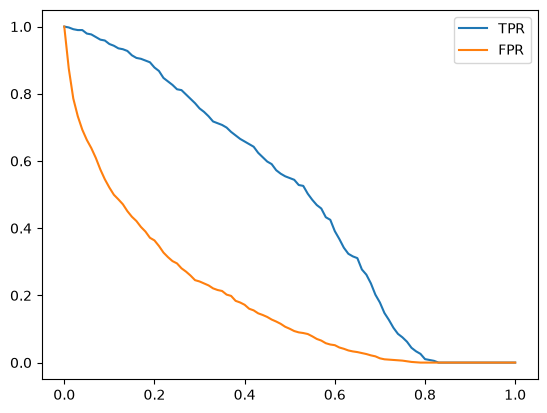

In [43]:
plt.plot(df_scores.threshold, df_scores.tpr, label='TPR')
plt.plot(df_scores.threshold, df_scores.fpr, label='FPR')
plt.legend()

#### === The random model ===

In [44]:
np.random.seed(1)

y_rand = np.random.uniform(0, 1, size=len(y_val))

In [45]:
def tpr_fpr_dataframe(y_pred, y_val):

    scores = []
    
    thresholds = np.linspace(0, 1, 101)
    
    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)
        
        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
    
        scores.append([t, tp, fp, fn, tn])
    
    df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn'])
    
    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    
    return df_scores

In [46]:
df_scores_rand = tpr_fpr_dataframe(y_rand, y_val)

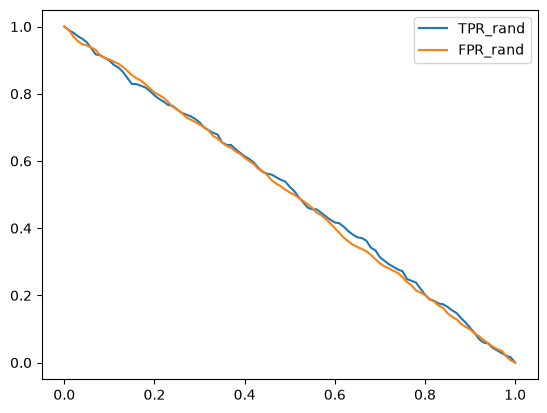

In [47]:
plt.plot(df_scores_rand.threshold, df_scores_rand.tpr, label='TPR_rand')
plt.plot(df_scores_rand.threshold, df_scores_rand.fpr, label='FPR_rand')
plt.legend()

#### === The ideal model ===

In [48]:
y_val

0       0
1       0
2       0
3       1
4       0
       ..
1404    0
1405    1
1406    0
1407    1
1408    1
Name: churn, Length: 1409, dtype: int64

In [49]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

In [50]:
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [51]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos])

In [52]:
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [53]:
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [54]:
num_neg / (num_neg + num_pos)

np.float64(0.7260468417317246)

In [55]:
accuracy_score(y_ideal, y_ideal_pred >= 0.726)

1.0

In [56]:
df_scores_ideal = tpr_fpr_dataframe(y_ideal_pred, y_ideal)

In [57]:
df_scores_ideal

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,386,1023,0,0,1.000000,1.000000
1,0.01,386,1008,0,15,1.000000,0.985337
2,0.02,386,994,0,29,1.000000,0.971652
3,0.03,386,980,0,43,1.000000,0.957967
4,0.04,386,966,0,57,1.000000,0.944282
...,...,...,...,...,...,...,...
96,0.96,57,0,329,1023,0.147668,0.000000
97,0.97,43,0,343,1023,0.111399,0.000000
98,0.98,29,0,357,1023,0.075130,0.000000
99,0.99,15,0,371,1023,0.038860,0.000000


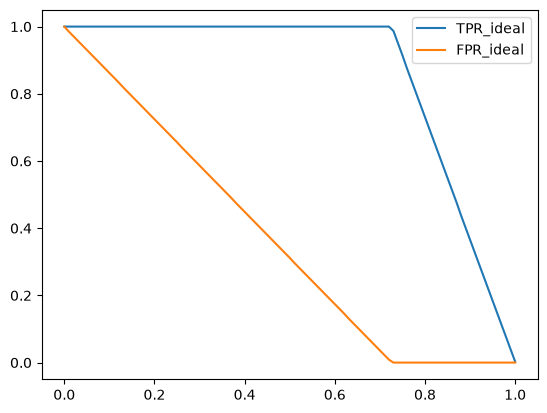

In [58]:
plt.plot(df_scores_ideal.threshold, df_scores_ideal.tpr, label='TPR_ideal')
plt.plot(df_scores_ideal.threshold, df_scores_ideal.fpr, label='FPR_ideal')
plt.legend()

#### === everything together ===

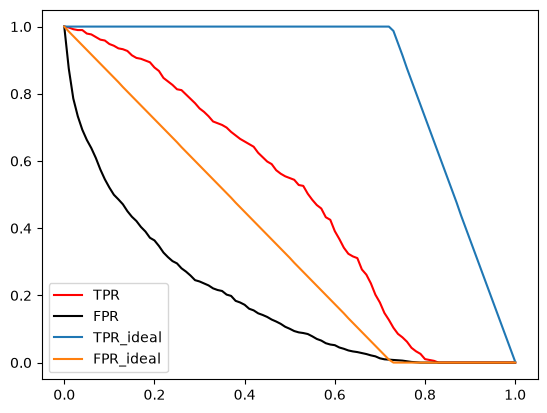

In [59]:
plt.plot(df_scores.threshold, df_scores.tpr, label='TPR', color='red')
plt.plot(df_scores.threshold, df_scores.fpr, label='FPR', color='black')

plt.plot(df_scores_ideal.threshold, df_scores_ideal.tpr, label='TPR_ideal')
plt.plot(df_scores_ideal.threshold, df_scores_ideal.fpr, label='FPR_ideal')

plt.legend()

In [60]:
# horizontal - Threshold
# vertical - TP/FP Rate

### The ROC curve

The ROC curve itself plots TPR against FPR - not against the threshold

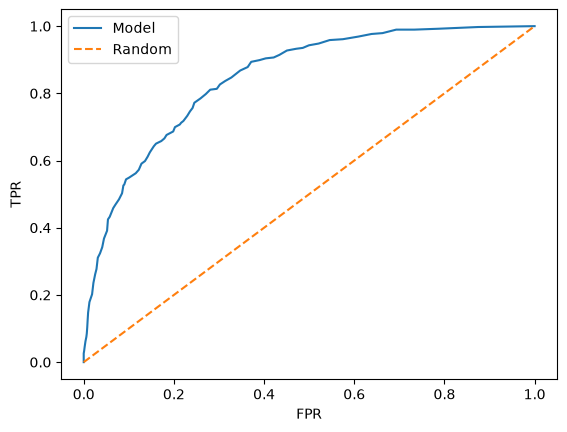

In [61]:
plt.plot(df_scores.fpr, df_scores.tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

### ROC curves with scikit-learn


In [62]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

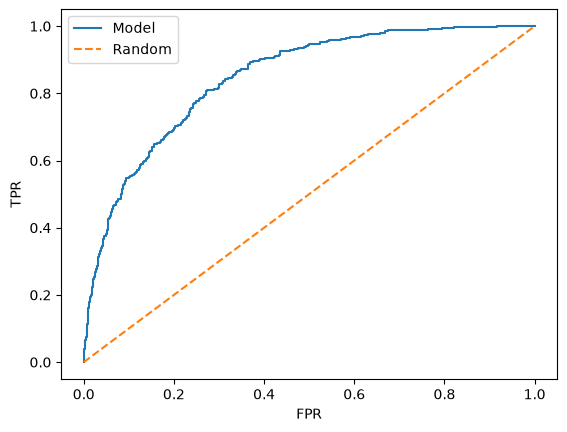

In [63]:
plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

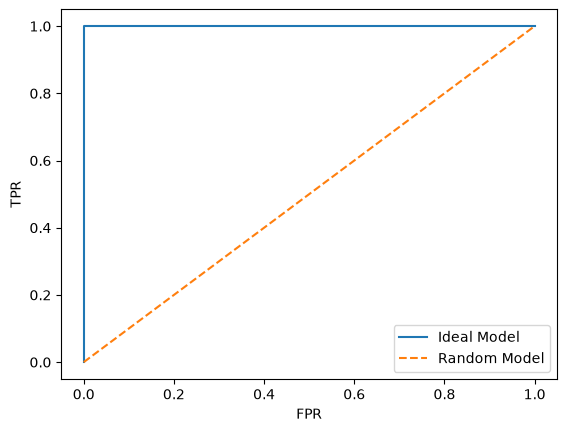

In [64]:
fpr_ideal_model, tpr_ideal_model, thresholds_ideal_model = roc_curve(y_ideal, y_ideal_pred)

plt.plot(fpr_ideal_model, tpr_ideal_model, label='Ideal Model')
plt.plot([0, 1], [0, 1], label='Random Model', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

### ROC AUC (= Area Under the Curve)

In [109]:
y_val

0       0
1       0
2       0
3       1
4       0
       ..
1404    0
1405    1
1406    0
1407    1
1408    1
Name: churn, Length: 1409, dtype: int64

In [110]:
y_pred

array([0.00667838, 0.20460366, 0.21752855, ..., 0.15209917, 0.78834393,
       0.81194359], shape=(1409,))

#### AUC

In [111]:
from sklearn.metrics import auc

auc(fpr, tpr)

0.8463753361797821

#### ROC AUC Score

In [112]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.8463753361797821

#### AUC as probability (by hands)

In [116]:
pos = y_pred[y_val == 1]
neg = y_pred[y_val == 0]

In [117]:
len(pos), len(neg)

(386, 1023)

In [118]:
import random

n = 1000000
success = 0

for i in range(n):
    pos_index = np.random.randint(0, len(pos) - 1)
    neg_index = np.random.randint(0, len(neg) - 1)

    if pos[pos_index] > neg[neg_index]:
        success += 1

success / n

0.846611

#### AUC as probability (vectoized)

In [122]:
n = 1000000

pos_index = np.random.randint(0, len(pos) - 1, n)
neg_index = np.random.randint(0, len(neg) - 1, n)

(pos[pos_index] > neg[neg_index]).mean()

np.float64(0.845374)

### 07. Cross validation

In [130]:
df_full_train

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
1814,5442-pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
5946,6261-rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
3881,2176-osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
2389,6161-erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
3676,2364-ufrom,male,0,no,no,30,yes,no,dsl,yes,...,no,yes,yes,no,one_year,no,electronic_check,70.40,2044.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
905,0781-lkxbr,male,1,no,no,9,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month-to-month,yes,electronic_check,100.50,918.60,1
5192,3507-gasnp,male,0,no,yes,60,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.95,1189.90,0
3980,8868-wozgu,male,0,no,no,28,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month-to-month,yes,electronic_check,105.70,2979.50,1
235,1251-krreg,male,0,no,no,2,yes,yes,dsl,no,...,no,no,no,no,month-to-month,yes,mailed_check,54.40,114.10,1


In [131]:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

In [132]:
len(df_full_train), len(df_train) + len(df_val)

(5634, 5634)

In [140]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=10000)
    model.fit(X_train, y_train)

    return dv, model

In [141]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [136]:
%pip install tqdm


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [142]:
from tqdm.auto import tqdm

In [143]:
from sklearn.model_selection import KFold

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009
C=0.01 0.840 +- 0.008
C=0.1 0.842 +- 0.007
C=0.5 0.842 +- 0.007
C=1 0.842 +- 0.007
C=5 0.842 +- 0.007
C=10 0.842 +- 0.007


In [145]:
scores

[0.843909695347395,
 0.8447370381406436,
 0.8336704796307445,
 0.8347888821385175,
 0.8520520222145525]

#### Training the final model

In [148]:
dv, model = train(df_full_train, df_full_train.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.858373416967294